# 10 — From apparent edge to trading economics

**Question:** What survives the spread, size, execution delay and uncertain outcomes?

**By the end:** distinguish expected profit from guaranteed profit, apply displayed
depth limits, understand maker uncertainty, and explain what a $3 EV target requires.
**Time:** 35–45 minutes. **Inputs:** recorded books plus explicitly hypothetical
probabilities, a $1 endpoint payout and USD-denominated per-share fee scenarios.

No scenario fee below is asserted to be the historical provider fee. Actual fees
can involve other units, rounding and order rules. No real orders are placed.

In [1]:
import sys
from pathlib import Path

for directory in (Path.cwd(), *Path.cwd().parents):
    if (directory / "src/tyrex_pm").exists():
        sys.path.insert(0, str(directory / "src"))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from tyrex_pm.research.tuto_btc5m.advanced import (
    ev_size,
)
from tyrex_pm.research.tuto_btc5m.analysis import (
    BookStudy,
    finish_plot,
    paired_quotes,
    plot_style,
    walk_book,
)
from tyrex_pm.research.tuto_btc5m.data import NS, Sample

SAMPLE_PATH = None  # Or Path("/absolute/path/to/your/prepared_sample")
sample = Sample.open(SAMPLE_PATH)
plot_style()
pd.set_option("display.max_columns", 12)
display(pd.Series(sample.describe(), name="Pinned input"))

collection                             2dd3d0d125dc4a9fb5e50daf3f9bfd3e
market                polymarket:condition:0x540c56b66edcf6f1273c7d7...
start_utc                                     2026-10-01 15:45:00+00:00
end_utc                                       2026-10-01 15:50:00+00:00
manifest_sha256       f5a2aa939c7d60a1f48d1f6df5c0110a61dc11a7794458...
integrity_scope       selected_normalized_parts_and_sample_only_not_...
semantic_readiness                                          UNSUPPORTED
Name: Pinned input, dtype: object

## 1. Expected value is an average over outcomes

For the hypothetical $1 binary and an all-in cost c = price + fee per share:

\[
\mathbb E[\Pi]=N(q-c),\qquad
\Pi_{win}=N(1-c),\quad \Pi_{lose}=-Nc.
\]

Choosing N = ceil(3 / (q − c)) targets about $3 **expected** profit when q > c.
It does not force every trade to win. q is an assumption, not a known truth.
All N shares of this same contract share one outcome; risk does not diversify by
buying more shares. Its standard deviation is N sqrt(q(1 − q)), not sqrt(N) times it.

In [2]:
scenarios = pd.DataFrame(
    [
        {"assumed_q": q, "assumed_fee_USD_per_share": fee, **ev_size(q, 0.70, fee)}
        for q in [0.70, 0.73, 0.75, 0.80]
        for fee in [0, 0.01, 0.02]
    ]
)
display(
    scenarios[
        [
            "assumed_q",
            "assumed_fee_USD_per_share",
            "net_edge_per_share_USD",
            "shares_for_target_EV",
            "shares_with_cash_cap",
            "capital_USD",
            "expected_profit_USD",
            "target_feasible_under_cap",
        ]
    ]
)
worked = ev_size(0.75, 0.70, 0.02)
display(pd.Series(worked, name="Hypothetical q=.75, price=.70, fee=.02, $100 cap"))

,assumed_q,assumed_fee_USD_per_share,net_edge_per_share_USD,shares_for_target_EV,shares_with_cash_cap,capital_USD,expected_profit_USD,target_feasible_under_cap
0,0.70,0.00,0.00,NaN,0,0.00,0.00,False
1,0.70,0.01,-0.01,NaN,0,0.00,-0.00,False
2,0.70,0.02,-0.02,NaN,0,0.00,-0.00,False
3,0.73,0.00,0.03,100.0,100,70.00,3.00,True
4,0.73,0.01,0.02,150.0,140,99.40,2.80,False
5,0.73,0.02,0.01,300.0,138,99.36,1.38,False
6,0.75,0.00,0.05,60.0,60,42.00,3.00,True
7,0.75,0.01,0.04,75.0,75,53.25,3.00,True
8,0.75,0.02,0.03,100.0,100,72.00,3.00,True
9,0.80,0.00,0.10,30.0,30,21.00,3.00,True


net_edge_per_share_USD            0.03
shares_for_target_EV               100
shares_with_cash_cap               100
capital_USD                       72.0
expected_profit_USD                3.0
target_feasible_under_cap         True
profit_if_win_USD                 28.0
profit_if_lose_USD               -72.0
pnl_standard_deviation_USD    43.30127
Name: Hypothetical q=.75, price=.70, fee=.02, $100 cap, dtype: object

## 2. A $3 mean can sit between much larger wins and losses

The next chart displays the two possible profits in the worked example and their
assumed probabilities. Increasing size scales both outcomes and the expected value.
There are no independent bets hidden inside one hundred shares of one contract.

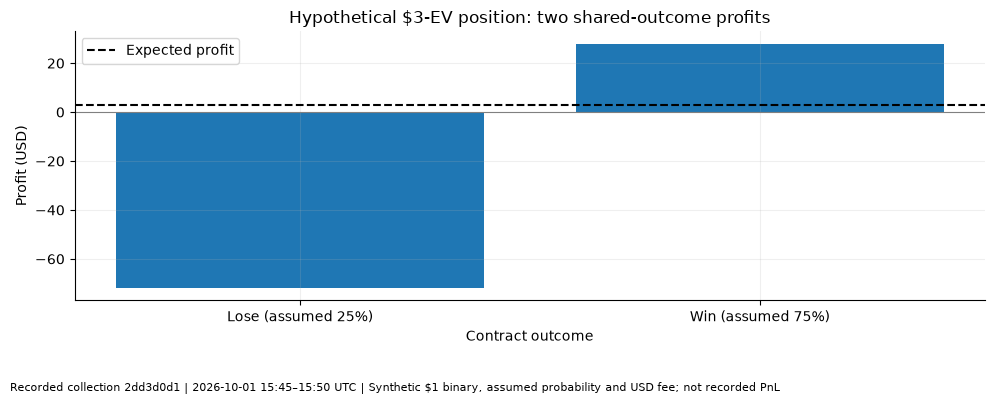

In [3]:
fig, ax = plt.subplots()
ax.bar(
    ["Lose (assumed 25%)", "Win (assumed 75%)"],
    [worked["profit_if_lose_USD"], worked["profit_if_win_USD"]],
)
ax.axhline(worked["expected_profit_USD"], linestyle="--", color="black", label="Expected profit")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(
    title="Hypothetical $3-EV position: two shared-outcome profits",
    xlabel="Contract outcome",
    ylabel="Profit (USD)",
)
ax.legend()
finish_plot(fig, sample, "Synthetic $1 binary, assumed probability and USD fee; not recorded PnL")

## 3. Apply the recorded book to size-dependent costs

We select an eligible time near the first quarter of the window, not a winning
trade. The book walk is exact displayed-depth arithmetic. It ignores our own
impact and assumes those orders remain available when we act.

,requested_shares,displayed_fill_shares,unfilled_shares,cash_before_fees,vwap,complete
0,10,10.000000000000000000000000000000,0E-30,8.14730000000000000000000000000000000000000000...,0.814730000000000000000000000000,True
1,50,50.000000000000000000000000000000,0E-30,40.9473000000000000000000000000000000000000000...,0.818946000000000000000000000000,True
2,100,100.000000000000000000000000000000,0E-30,81.9473000000000000000000000000000000000000000...,0.819473000000000000000000000000,True
3,250,250.000000000000000000000000000000,0E-30,205.289600000000000000000000000000000000000000...,0.821158400000000000000000000000,True
4,500,500.000000000000000000000000000000,0E-30,412.789600000000000000000000000000000000000000...,0.825579200000000000000000000000,True


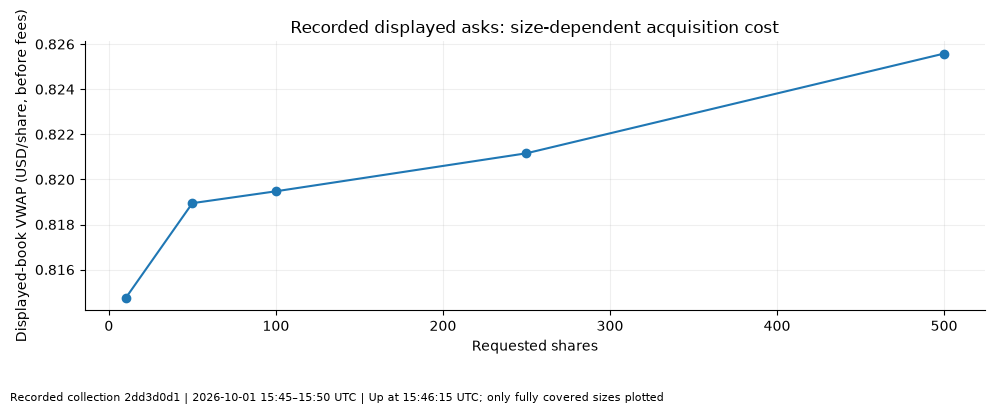

In [4]:
study = BookStudy(sample)
grid = study.grid()
iid = next(i for i, label in sample.labels.items() if str(label).lower() == "up")
up = grid[grid.instrument_id == iid].copy()
candidates = up[up.analysis_eligible]
target = pd.Timestamp(sample.start + 75 * NS, tz="UTC")
chosen = candidates.loc[(candidates.time - target).abs().idxmin()]
book = study.book_at(iid, chosen.time.value)
costs = pd.DataFrame([walk_book(book, size) for size in [10, 50, 100, 250, 500]])
display(costs)
fig, ax = plt.subplots()
complete = costs[costs.complete]
ax.plot(complete.requested_shares.map(float), complete.vwap.map(float), marker="o")
ax.set(
    title="Recorded displayed asks: size-dependent acquisition cost",
    xlabel="Requested shares",
    ylabel="Displayed-book VWAP (USD/share, before fees)",
)
finish_plot(fig, sample, f"Up at {chosen.time:%H:%M:%S} UTC; only fully covered sizes plotted")

## 4. Price movement during delay changes the opportunity

We compare a hypothetical buy at the chosen static ask ladder with later static
sell ladders. The table is a **retrospective markout scenario**, not an actual fill,
stop-loss guarantee or strategy backtest. Missing later books are recorded as
unavailable. Adding a $0.01 entry and $0.01 exit fee per share is another declared
scenario, not a provider fee formula.

,delay_s,gross_static_markout_USD,with_hypothetical_2c_roundtrip_fee_USD,status
0,0,-0.1473,-0.3473,displayed depth only
1,1,0.0527,-0.1473,displayed depth only
2,3,0.4527,0.2527,displayed depth only
3,5,1.0527,0.8527,displayed depth only
4,10,1.2527,1.0527,displayed depth only


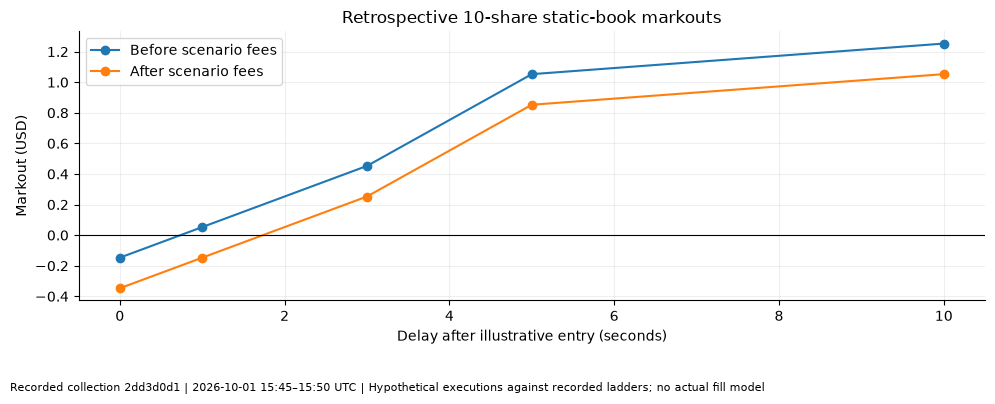

In [5]:
entry = walk_book(book, 10, "buy")
markouts = []
for delay in [0, 1, 3, 5, 10]:
    try:
        later_book = study.book_at(iid, chosen.time.value + delay * NS)
        exit_quote = walk_book(later_book, 10, "sell")
        complete = entry["complete"] and exit_quote["complete"]
        gross = (
            float(exit_quote["cash_before_fees"] - entry["cash_before_fees"])
            if complete
            else np.nan
        )
        markouts.append(
            {
                "delay_s": delay,
                "gross_static_markout_USD": gross,
                "with_hypothetical_2c_roundtrip_fee_USD": gross - 0.20,
                "status": "displayed depth only" if complete else "partial depth",
            }
        )
    except ValueError:
        markouts.append(
            {
                "delay_s": delay,
                "gross_static_markout_USD": np.nan,
                "with_hypothetical_2c_roundtrip_fee_USD": np.nan,
                "status": "unavailable book",
            }
        )
markouts = pd.DataFrame(markouts)
display(markouts)
if markouts.gross_static_markout_USD.notna().any():
    fig, ax = plt.subplots()
    ax.plot(
        markouts.delay_s,
        markouts.gross_static_markout_USD,
        marker="o",
        label="Before scenario fees",
    )
    ax.plot(
        markouts.delay_s,
        markouts.with_hypothetical_2c_roundtrip_fee_USD,
        marker="o",
        label="After scenario fees",
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(
        title="Retrospective 10-share static-book markouts",
        xlabel="Delay after illustrative entry (seconds)",
        ylabel="Markout (USD)",
    )
    ax.legend()
    finish_plot(
        fig, sample, "Hypothetical executions against recorded ladders; no actual fill model"
    )

## 5. A quoted pair and a maker fill have different risks

For an illustrative qualified complete set, both asks summing below $1 is a price
condition, not proof of two fills. Required quantities, fees, delay and merge or
redemption mechanics matter. Two resting bids are especially exposed to an orphan
fill: only the side informed flow wanted to sell may execute.

A maker quote touching the market does not prove our queue position or fill.
Likewise, a stop does not guarantee its requested execution price during a jump.

In [6]:
pair = paired_quotes(grid)
display(
    pd.Series(
        {
            "both_eligible_grid_points": int(pair.both_eligible.sum()),
            "ask_sum_below_1_before_any_costs": int((pair.ask_sum < 1).sum()),
            "atomic_pair_fills_observed": "not inferable from public book",
            "maker_queue_position": "not recorded",
        }
    )
)

both_eligible_grid_points                                      176
ask_sum_below_1_before_any_costs                                 0
atomic_pair_fills_observed          not inferable from public book
maker_queue_position                                  not recorded
dtype: object

## Exercise — challenge the sizing identity

Change q from .75 to .72 in the worked scenario. What happens to the edge, size
and worst outcome? Why does a larger position not solve model uncertainty?

**Suggested answer:** an assumed edge shrinks or vanishes after costs. Size can
grow beyond the capital/depth cap, and if the true q is lower, extra size amplifies
the estimation error. $3 EV is neither $3 minimum profit nor a sizing recommendation.

**Research use:** execution costs and risk constrain a candidate signal before
live implementation. **Next:** [11 — Research tests](11_hypotheses_and_uncertainty.ipynb).